In this notebook 3 different Neural Networks approach are tried:
- **Deep Sets**
- **Point Net**
- **Graph Neural Network**

# 00 - General Operations

In [1]:
import os
import numpy as np 
import pandas as pd
import re
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import re
import sys
from tqdm import tqdm

os.environ["KERAS_BACKEND"] = "tensorflow"  
import keras
from keras import layers, ops
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report, precision_score, recall_score
from sklearn.model_selection import train_test_split

sys.path.append(str(Path("../../src/models").resolve()))
from deepsets import build_deepsets
from pointnet import build_pointnet
from graphnn import build_gnn, Adjacency

In [2]:
random_state = 42
keras.utils.set_random_seed(random_state)
test_size = 0.2

EPOCHS = 30 #60
BATCH_SIZE = 512 

families_dict = {
    # Neutral_Background
    "AlbedoPhotons" : "Neutral_Background",
    "AtmosphericNeutrons" : "Neutral_Background",
    "CosmicPhotons" : "Neutral_Background",

    # TEMP: tgf
    #"TGF": "Neutral_Background",
    "TGF" : "TGF",
    
    # EM_Primary 
    "PrimaryElectrons" : "EM_Primary",
    "PrimaryPositrons" : "EM_Primary",

    # EM_Secondary
    "SecondaryElectrons" : "EM_Secondary",
    "SecondaryPositrons" : "EM_Secondary",

    # Hadronic_Heavy
    "PrimaryProtons" : "Hadronic_Heavy",
    "PrimaryAlphas" : "Hadronic_Heavy",
    "SecondaryProtonsUpward" : "Hadronic_Heavy",
    "SecondaryProtonsDownward" : "Hadronic_Heavy"
}

path = "../../Data/Background/Background_primary_fixed"
hits_csv = "/csv/hits.csv"
paths = {
    "AlbedoPhotons": f"{path}/AlbedoPhotons_20260917_160430{hits_csv}",
    "AtmosphericNeutrons": f"{path}/AtmosphericNeutrons_20261013_144421{hits_csv}",
    "CosmicPhotons": f"{path}/CosmicPhotons_20260917_161711{hits_csv}",
    "PrimaryAlphas": f"{path}/PrimaryAlphas_20261013_144552{hits_csv}",
    "PrimaryElectrons": f"{path}/PrimaryElectrons_20261013_141713{hits_csv}",
    "PrimaryPositrons": f"{path}/PrimaryPositrons_20261013_142349{hits_csv}",
    "PrimaryProtons": f"{path}/PrimaryProtons_20260917_163703{hits_csv}",
    "SecondaryElectrons": f"{path}/SecondaryElectrons_20260917_164325{hits_csv}",
    "SecondaryPositrons": f"{path}/SecondaryPositrons_20260917_164524{hits_csv}",
    "SecondaryProtonsDownward": f"{path}/SecondaryProtonsDownward_20260917_165127{hits_csv}",
    "SecondaryProtonsUpward": f"{path}/SecondaryProtonsUpward_20260917_165336{hits_csv}",
}
tgf_root = "../../data/TGF/TGF_different_directions/HELPix_TGF_LUT/"

## 00.1 - Function declaration

Next cell contain the function to read and process the `hits.csv` files.

In [3]:
def _events_from_hits(df, min_hits, merge_same_voxel=True):
    """
    df: hit rows with columns event_index, pixel_ijk, edep_kev (whole events only).
    merge_same_voxel: if true merge the hit if that voxel received more than 1 hit
    """

    if len(df) == 0:
        return [], np.array([], dtype=int)
    
    ijk = df["pixel_ijk"].str.strip("[] ").str.split(",", expand=True).astype(int)
    df = pd.DataFrame({
        "event_index": df["event_index"].to_numpy(),
        "i": ijk[0].to_numpy(), "j": ijk[1].to_numpy(), "k": ijk[2].to_numpy(),
        "edep_kev": df["edep_kev"].to_numpy()
    })
    if merge_same_voxel:
        df = df.groupby(["event_index", "i", "j", "k"], as_index=False)["edep_kev"].sum()
    df = df.sort_values("event_index", kind="stable")
    hits = df[["i", "j", "k", "edep_kev"]].to_numpy(dtype="float64")
    ids = df["event_index"].to_numpy()

    boundaries = np.flatnonzero(np.diff(ids)) + 1          # cut where event_index changes
    events = np.split(hits, boundaries)
    event_ids = ids[np.r_[0, boundaries]]                  # translator object
    keep = [n for n, ev in enumerate(events) if len(ev) >= min_hits]
    return [events[n] for n in keep], event_ids[keep]


def load_events(csv_path, min_hits=3, merge_same_voxel=True, max_events=None, chunksize=500_000):
    """
    Read a hit-level CSV and group the hits by event.

    max_events=None : read the whole file.
    max_events=N    : read the file in blocks and STOP as soon as N events with >= min_hits hits are
                      found (the first N in file order). Much faster for big files.
                      Needs the rows of each event to be consecutive (file sorted by event_index).

    Returns: events (list of (n_hits, 4) arrays = [i, j, k, energy_keV]), event_ids
    """
    cols = ["event_index", "pixel_ijk", "edep_kev"]
    if max_events is None:
        return _events_from_hits(pd.read_csv(csv_path, usecols=cols), min_hits, merge_same_voxel)

    events, ids = [], []
    leftover = None                                        # last event of a block may continue in the next block
    for chunk in pd.read_csv(csv_path, usecols=cols, chunksize=chunksize):
        if not chunk["event_index"].is_monotonic_increasing:
            raise ValueError(f"{csv_path}: rows are not sorted by event_index, use max_events=None")
        df = chunk if leftover is None else pd.concat([leftover, chunk], ignore_index=True)
        last = df["event_index"].iloc[-1]
        leftover = df[df["event_index"] == last]           # keep the possibly incomplete event for later
        ev, ev_ids = _events_from_hits(df[df["event_index"] != last], min_hits, merge_same_voxel)
        events += ev
        ids += list(ev_ids)
        if len(events) >= max_events:
            return events[:max_events], np.array(ids[:max_events])

    if leftover is not None and len(events) < max_events:  # end of file: the last event is complete
        ev, ev_ids = _events_from_hits(leftover, min_hits, merge_same_voxel)
        events += ev
        ids += list(ev_ids)
    return events[:max_events], np.array(ids[:max_events])


def load_tgf(root, n_per_direction=1000, min_hits=3, **kwargs):
    """
    Read the TGF simulations, one folder per direction:
         root/TGF_healpix_LUT16_nside16_pix<N>/csv_allhits/hits.csv

    Returns
      events     : list of (n_hits, 4) arrays
      directions : array with the pixel number N of each event
      event_ids  : array with the event_index of each event (NOT unique across directions)
    """
    folders = sorted(Path(root).glob("TGF_healpix_LUT16_nside16_pix*"),
                     key=lambda p: int(re.search(r"pix(\d+)$", p.name).group(1)))
    events, directions, ids = [], [], []
    for folder in tqdm(folders, desc=f"Reading {n_per_direction} events for each TGF files..."):
        csv_path = folder / "csv_allhits" / "hits.csv"
        if not csv_path.exists():
            print(f"missing: {csv_path}")
            continue
        ev, ev_ids = load_events(csv_path, min_hits=min_hits, max_events=n_per_direction, **kwargs)
        pix = int(re.search(r"pix(\d+)$", folder.name).group(1))
        events += ev
        directions += [pix] * len(ev)
        ids.append(ev_ids)
        # print(f"pix{pix}: {len(ev)} events")
    return events, np.array(directions), np.concatenate(ids)


def load_all(paths_by_type, **kwargs):
    """
    paths_by_type: {"PrimaryProtons": "protons/hits.csv", ...}   (one hit-level CSV per particle type)
    Returns events, particle_type (one label per event), event_ids.
    """
    events, labels, ids = [], [], []
    for particle_type, path in tqdm(paths_by_type.items(), desc="Reading background files!"):
        ev, ev_ids = load_events(path, **kwargs)
        events += ev
        labels += [particle_type] * len(ev)
        ids.append(ev_ids)
        # print(f"{particle_type}: {len(ev)} events")
    return events, np.array(labels), np.concatenate(ids)

The next cell contains functions to prepare data for the models. One function will process the event and generate the set to give to the models, the other fucntion will convert the set into tensors:

In [ ]:
MAX_HITS = 64                                             # The max number of hit processed
SAT_EDGE_DIM = 10
VOXEL_CENTER = VOXEL_HALF_SIZE = (SAT_EDGE_DIM - 1) / 2    # because indexes goes from 0 to N-1

def encode_event(event, max_hits):
    """
    Turn one event (array of shape (n_hits, 4) with columns i, j, k, energy)
    into one row of 8 numbers per hit, keeping at most `max_hits` hits.
    """
    
    n_hits_total = len(event)
    energy_total = event[:, 3].sum()

    # Keep only the most energetic hits (sorted from highest to lowest energy)
    event = event[np.argsort(-event[:, 3])][:max_hits]

    voxel = event[:, :3]                      
    energy = event[:, 3]                      

    # Energy-weighted centre of the event
    centroid = (voxel * energy[:, None]).sum(axis=0) / energy.sum()

    hit_rows = np.column_stack([
        (voxel - VOXEL_CENTER) / VOXEL_HALF_SIZE,      # 3 numbers: position in the detector, from -1 to +1
        (voxel - centroid) / VOXEL_HALF_SIZE,          # 3 numbers: position relative to the event centre
        np.log1p(energy),                              # 1  number: energy on a log scale
        energy / energy_total,                         # 1 number: fraction of the event energy
    ])
    return hit_rows, n_hits_total, energy_total


def build_tensors(events, max_hits=MAX_HITS):
    """
    events: list of arrays, one per event, each of shape (n_hits, 4) = [i, j, k, energy].
    Returns:
      hit_features   (n_events, max_hits, 8)  numbers describing each hit (zeros where there is no hit)
      hit_mask       (n_events, max_hits)     1 = real hit, 0 = padding
      event_features (n_events, 2)            log(number of hits), log(total energy) of the event
    """
    n_events = len(events)
    hit_features = np.zeros((n_events, max_hits, 8), dtype="float32")
    hit_mask = np.zeros((n_events, max_hits), dtype="float32")
    event_features = np.zeros((n_events, 2), dtype="float32")

    for n, event in enumerate(events):
        hit_rows, n_hits_total, energy_total = encode_event(event, max_hits)
        n_kept = len(hit_rows)

        hit_features[n, :n_kept] = hit_rows       # fill the first n_kept slots, the rest stays 0 (padding)
        hit_mask[n, :n_kept] = 1
        event_features[n] = [np.log1p(n_hits_total), np.log1p(energy_total)]

    return hit_features, hit_mask, event_features

Define the function to train the models:

In [5]:
def sub(arrays, idx): 
    return [a[idx] for a in arrays]

def fit_eval(model, X, train_set, test_set, model_name, weight_all):
    fit_idx, val_idx = train_test_split(train_set, test_size=0.1, stratify=y_int[train_set], random_state=random_state)

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy", 
        metrics=["accuracy"]
    )
    model.fit(
        sub(X, fit_idx), 
        y_int[fit_idx], 
        sample_weight=weight_all[fit_idx],
        validation_data=(sub(X, val_idx), y_int[val_idx], weight_all[val_idx]),
        epochs=EPOCHS, 
        batch_size=BATCH_SIZE, 
        verbose=2,
        callbacks=[
            keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3)]
        )
    p = model.predict(sub(X, test_set), batch_size=2048)
    print(f"{model_name}: macro-F1 test = {f1_score(y_int[test_set], p.argmax(1), average='macro'):.3f}")
    return p

## 00.2 - Data reading and processing

TGF is the majority of the events: the imbalance is handled with per-event class weights in the loss and in the validation loss.

Here we use a set of 3D hit $\{h_1, \dots, h_N\}$ where $N \le$ `MAX_HITS` (completed with *zero-padding*). The feature used are:
- For every hit (8 dim): normalized coords $(i, j, k) \in [-1, 1]^3$, relative coords wrt COM of the event, energy store ( $\log(1 + E)$) and fraction of energy in that hit $E / E_{\text{tot}}$.
- Gloabal features (2 dim): (concatenated after pooling): $\log(1 + N_{\text{hits}})$ e $\log(1 + E_{\text{tot}})$.


In [6]:
# read the hits of bg and tgf
bg_events, particle_type, event_ids = load_all(paths)
# print(pd.Series(particle_type).value_counts())  
tgf_events, tgf_direction, tgf_ids = load_tgf(tgf_root, n_per_direction=150)

# get every events (bg + tgf)
events = bg_events + tgf_events
particle_type_all = np.concatenate([particle_type, np.full(len(tgf_events), "TGF")])
print(pd.Series(particle_type_all).value_counts()) 

Reading 150 events for each TGF files...: 100%|██████████| 928/928 [05:15<00:00,  2.94it/s]

TGF                         139200
SecondaryPositrons           17146
PrimaryPositrons             14694
PrimaryProtons               12751
AlbedoPhotons                 8790
PrimaryAlphas                 7630
PrimaryElectrons              6520
SecondaryProtonsUpward        4652
SecondaryProtonsDownward      4314
SecondaryElectrons            4207
AtmosphericNeutrons           2118
CosmicPhotons                 1925
Name: count, dtype: int64


In [7]:
# map to family, obtain classes and convert them to integer
family = pd.Series(particle_type_all).map(families_dict)
classes = np.sort(family.unique())
y_int = family.map({c: i for i, c in enumerate(classes)}).to_numpy()

H, V, G = build_tensors(events)

In [8]:
# split and class weight computing to handle the unbalanced dataset
tr, te = train_test_split(np.arange(len(y_int)), test_size=test_size, stratify=y_int, random_state=random_state)
cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(len(classes)), y=y_int[tr])))
w_all = np.array([cw[c] for c in y_int], dtype="float32")     # one weight per event, from the class weights

In [9]:
print(f"Hit features: {H.shape}, valid-hit mask: {V.shape}, global features: {G.shape}")
print("Train/test split:", len(tr), len(te), "events, class distribution:", pd.Series(y_int[tr]).value_counts().to_dict())
print("Train class distribution:", pd.Series(y_int[tr]).value_counts().to_dict())
print("Test class distribution:", pd.Series(y_int[te]).value_counts().to_dict())

Hit features: (223947, 64, 8), valid-hit mask: (223947, 64), global features: (223947, 2)
Train/test split: 179157 44790 events, class distribution: {4: 111360, 2: 23478, 1: 17082, 0: 16971, 3: 10266}
Train class distribution: {4: 111360, 2: 23478, 1: 17082, 0: 16971, 3: 10266}
Test class distribution: {4: 27840, 2: 5869, 1: 4271, 0: 4243, 3: 2567}


In [10]:
X = [H, V, G]

# 01 - Deepsets

DeepSets applies the same MLP to every hit, then aggregates the hits with a pooling (`mean` + `max`) to guarantee the ***permutation invariance***, and finally classifies with a second MLP.

In [11]:
deepset_model = build_deepsets(len(classes))
pred_deepset = fit_eval(deepset_model, X, tr, te, "DeepSets", w_all)

Epoch 1/30
315/315 - 8s - 27ms/step - accuracy: 0.5965 - loss: 1.1389 - val_accuracy: 0.7116 - val_loss: 0.9270 - learning_rate: 0.0010
Epoch 2/30
315/315 - 7s - 21ms/step - accuracy: 0.7016 - loss: 0.8990 - val_accuracy: 0.7113 - val_loss: 0.8620 - learning_rate: 0.0010
Epoch 3/30
315/315 - 9s - 27ms/step - accuracy: 0.7143 - loss: 0.8554 - val_accuracy: 0.7230 - val_loss: 0.8415 - learning_rate: 0.0010
Epoch 4/30
315/315 - 8s - 25ms/step - accuracy: 0.7184 - loss: 0.8315 - val_accuracy: 0.7408 - val_loss: 0.8222 - learning_rate: 0.0010
Epoch 5/30
315/315 - 7s - 22ms/step - accuracy: 0.7212 - loss: 0.8164 - val_accuracy: 0.7463 - val_loss: 0.8133 - learning_rate: 0.0010
Epoch 6/30
315/315 - 8s - 26ms/step - accuracy: 0.7240 - loss: 0.8062 - val_accuracy: 0.7396 - val_loss: 0.8098 - learning_rate: 0.0010
Epoch 7/30
315/315 - 8s - 24ms/step - accuracy: 0.7268 - loss: 0.7990 - val_accuracy: 0.7531 - val_loss: 0.7993 - learning_rate: 0.0010
Epoch 8/30
315/315 - 7s - 22ms/step - accuracy: 

An important feature of the deepset model is that it must be permutation invariant, let's check if the model respect this:

In [12]:
perm = np.random.default_rng(1).permutation(MAX_HITS)
pred_deepset_test = deepset_model.predict([H[te][:, perm], V[te][:, perm], G[te]])
print("CHECK ON PERMUTATION INVARIANCE: difference after permutation:", np.abs(pred_deepset - pred_deepset_test).max())   

1400/1400 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  
CHECK ON PERMUTATION INVARIANCE: difference after permutation: 7.748604e-07


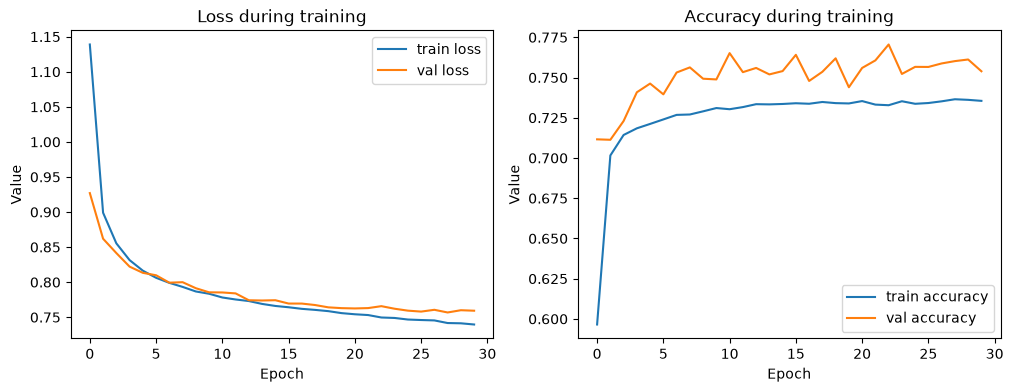

In [13]:
axes = plt.subplots(1, 2, figsize=(12, 4))[1]


axes[0].plot(deepset_model.history.history["loss"], label="train loss")
axes[0].plot(deepset_model.history.history["val_loss"], label="val loss")
axes[1].plot(deepset_model.history.history["accuracy"], label="train accuracy")
axes[1].plot(deepset_model.history.history["val_accuracy"], label="val accuracy")

axes[0].set_title("Loss during training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Value")
axes[0].legend()

axes[1].set_title("Accuracy during training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Value")
axes[1].legend()
plt.show()

predicted           EM_Primary  EM_Secondary  Hadronic_Heavy  \
true                                                           
EM_Primary               0.828         0.082           0.073   
EM_Secondary             0.047         0.616           0.082   
Hadronic_Heavy           0.083         0.090           0.795   
Neutral_Background       0.016         0.233           0.027   
TGF                      0.001         0.047           0.001   

predicted           Neutral_Background    TGF  
true                                           
EM_Primary                       0.008  0.009  
EM_Secondary                     0.064  0.191  
Hadronic_Heavy                   0.016  0.016  
Neutral_Background               0.461  0.262  
TGF                              0.159  0.792  


Text(0.5, 1.0, 'Confusion matrix (DeepSets)')

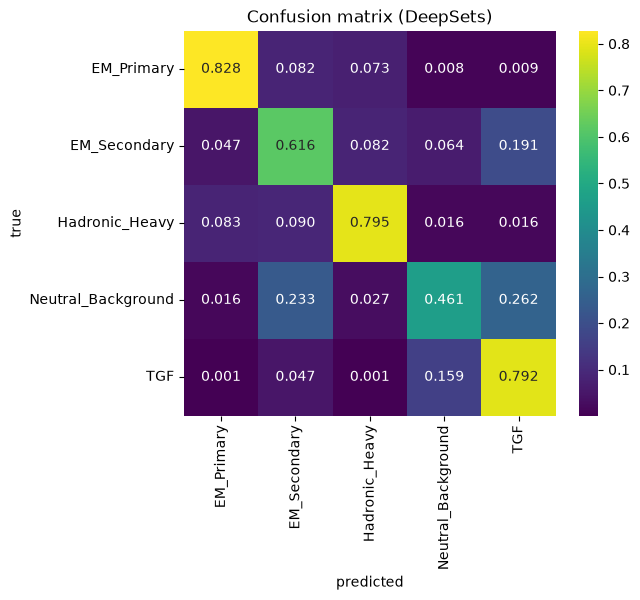

In [14]:
# print("macro-F1:", round(f1_score(y_int[te], pred_deepset, average="macro"), 3))

cm = pd.crosstab(
    pd.Series(classes[y_int[te]], name="true"),
    pd.Series(classes[pred_deepset.argmax(1)], name="predicted"), 
    normalize="index"
).round(3)
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=".3f", cmap="viridis",xticklabels=classes, yticklabels=classes)
plt.title("Confusion matrix (DeepSets)")

`Neutral_Background` is mostly confused with `EM_Secondary` and `TGF`, and of `EM_Secondary`. Training and validation losses stay close (no overfitting), but they stop improving, probably the information in the hits is the limit.

In [15]:
n_hits = np.array([len(e) for e in events])
print(f"Percentage of event with hits >= {MAX_HITS}")
print(pd.Series(n_hits > MAX_HITS).groupby(classes[y_int]).mean().round(3))

Percentage of event with hits >= 64
EM_Primary            0.257
EM_Secondary          0.002
Hadronic_Heavy        0.039
Neutral_Background    0.001
TGF                   0.000
dtype: float64


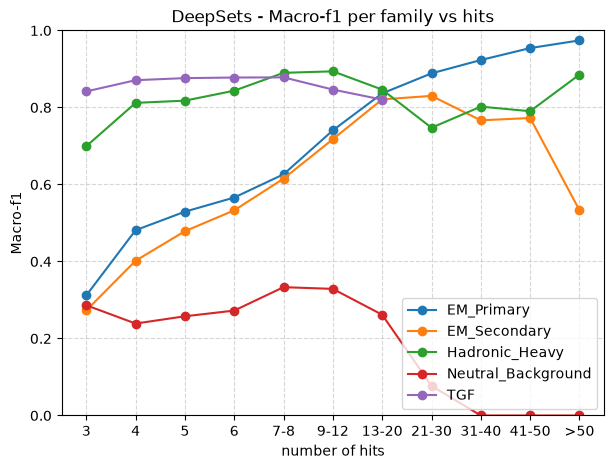

In [16]:
name = "DeepSets"                      # "PointNet" / "GNN"
pred = pred_deepset.argmax(1)
metric = "Macro-f1" # or Precision, Recall
if metric == "Macro-f1": metric_fn = f1_score
elif metric == "Precision": metric_fn = precision_score
else: metric_fn = recall_score

edges  = [2, 3, 4, 5, 6, 8, 12, 20, 30, 40, 50, np.inf]
labels = ["3", "4", "5", "6", "7-8", "9-12", "13-20", "21-30", "31-40", "41-50", ">50"]
hit_bins = pd.cut(n_hits[te], edges, labels=labels)
y_te = y_int[te]

plt.figure(figsize=(7, 5))
for k, fam in enumerate(classes):
    prec = [metric_fn(y_te[hit_bins == b] == k, pred[hit_bins == b] == k, zero_division=np.nan)
            for b in labels]
    plt.plot(labels, prec, "o-", label=fam)

plt.xlabel("number of hits"); plt.ylabel(metric); plt.ylim(0, 1)
plt.title(f"{name} - {metric} per family vs hits")
plt.grid(True, linestyle="--", alpha=0.5); plt.legend()
plt.show()

In [17]:
pred_check = pred_deepset.argmax(1)
y_te_check = y_int[te]

edges = [2, 3, 4, 5, 6, 8, 12, 20, 30, 40, 50, np.inf]
labels = [
    "3",
    "4",
    "5",
    "6",
    "7-8",
    "9-12",
    "13-20",
    "21-30",
    "31-40",
    "41-50",
    ">50",
]
hit_bins_check = pd.cut(n_hits[te], edges, labels=labels)

high_hit_bins = ["21-30", "31-40", "41-50", ">50"]

for b in high_hit_bins:
  m = hit_bins_check == b
  true_counts = pd.Series(classes[y_te_check[m]]).value_counts()
  pred_counts = pd.Series(classes[pred_check[m]]).value_counts()

  df_verify = (
      pd.DataFrame({
          "True_Events": true_counts,
          "Predicted_Events": pred_counts,
      })
      .reindex(classes)
      .fillna(0)
      .astype(int)
  )

  print(f"\n=== Bin hits: {b} (Tot events: {m.sum()}) ===")
  print(df_verify)


=== Bin hits: 21-30 (Tot events: 912) ===
                    True_Events  Predicted_Events
EM_Primary                  480               499
EM_Secondary                249               281
Hadronic_Heavy              158               131
Neutral_Background           25                 1
TGF                           0                 0

=== Bin hits: 31-40 (Tot events: 511) ===
                    True_Events  Predicted_Events
EM_Primary                  345               372
EM_Secondary                 58                62
Hadronic_Heavy              100                77
Neutral_Background            8                 0
TGF                           0                 0

=== Bin hits: 41-50 (Tot events: 403) ===
                    True_Events  Predicted_Events
EM_Primary                  308               327
EM_Secondary                 20                24
Hadronic_Heavy               72                52
Neutral_Background            3                 0
TGF                  

It's the fastest and high performace model wrt to the others in this notebook (**Test Macro-F1 = $0.665$**). 

It cannot divide properly `Neutral_Background` and `EM_Secondary`. 

`EM_Primary` ed `EM_Secondary` get better wrt the number of hit. `Neutral_Background` stays below $0.35$ and drops to $0.0$ above 30 hits: unlike TGF (which disappears from the plot as both true and predicted counts hit zero, yielding NaN), Neutral_Background runs out of true events while the model still makes a few false positives, pushing its F1-score straight to zero

# 02 - Pointnet

**PointNet** extend the representation for each hit to 256 dim (`64 -> 128 -> 256`) and uses a **Masked Global Max Pooling (`MaskedMax`)** instead of the `mean` + `max` approach.

It reaches macro-F1 equivalent to DeepSets (within small variability), but each epoch is about 4–5 times slower.

In [18]:
pointnet = build_pointnet(len(classes))              
# keras.utils.plot_model(pointnet, show_shapes=True)
prob_pn = fit_eval(pointnet, [H, V, G], tr, te, "PointNet", weight_all=w_all)   
# pointnet_history = pointnet.history

Epoch 1/30
315/315 - 30s - 96ms/step - accuracy: 0.6003 - loss: 1.1662 - val_accuracy: 0.7248 - val_loss: 0.9166 - learning_rate: 0.0010
Epoch 2/30
315/315 - 33s - 106ms/step - accuracy: 0.7036 - loss: 0.9025 - val_accuracy: 0.7372 - val_loss: 0.8575 - learning_rate: 0.0010
Epoch 3/30
315/315 - 33s - 105ms/step - accuracy: 0.7160 - loss: 0.8560 - val_accuracy: 0.7359 - val_loss: 0.8186 - learning_rate: 0.0010
Epoch 4/30
315/315 - 30s - 95ms/step - accuracy: 0.7208 - loss: 0.8319 - val_accuracy: 0.7575 - val_loss: 0.8054 - learning_rate: 0.0010
Epoch 5/30
315/315 - 33s - 106ms/step - accuracy: 0.7226 - loss: 0.8199 - val_accuracy: 0.7474 - val_loss: 0.8184 - learning_rate: 0.0010
Epoch 6/30
315/315 - 31s - 99ms/step - accuracy: 0.7259 - loss: 0.8110 - val_accuracy: 0.7336 - val_loss: 0.8239 - learning_rate: 0.0010
Epoch 7/30
315/315 - 28s - 88ms/step - accuracy: 0.7262 - loss: 0.7997 - val_accuracy: 0.7343 - val_loss: 0.8220 - learning_rate: 0.0010
Epoch 8/30
315/315 - 27s - 86ms/step -

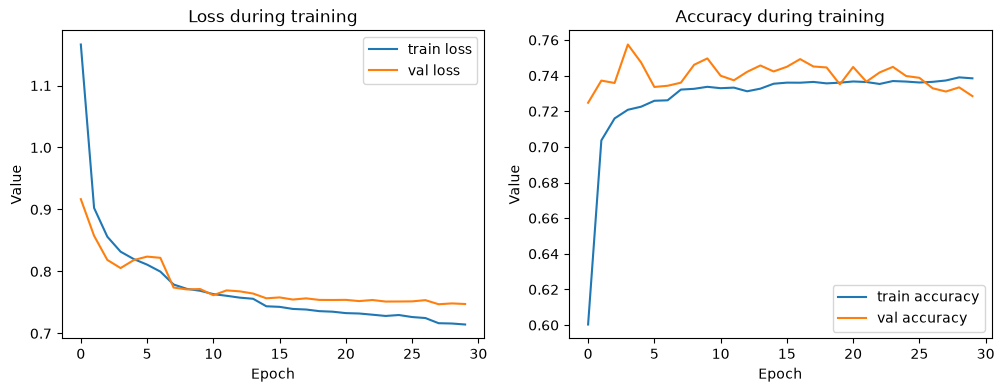

In [19]:
axes = plt.subplots(1, 2, figsize=(12, 4))[1]

axes[0].plot(pointnet.history.history["loss"], label="train loss")
axes[0].plot(pointnet.history.history["val_loss"], label="val loss")
axes[1].plot(pointnet.history.history["accuracy"], label="train accuracy")
axes[1].plot(pointnet.history.history["val_accuracy"], label="val accuracy")

axes[0].set_title("Loss during training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Value")
axes[0].legend()

axes[1].set_title("Accuracy during training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Value")
axes[1].legend()
plt.show()

macro-F1: 0.654
                    precision    recall  f1-score   support

        EM_Primary      0.825     0.814     0.819      4243
      EM_Secondary      0.451     0.628     0.525      4271
    Hadronic_Heavy      0.848     0.810     0.829      5869
Neutral_Background      0.185     0.514     0.272      2567
               TGF      0.939     0.739     0.827     27840

          accuracy                          0.732     44790
         macro avg      0.650     0.701     0.654     44790
      weighted avg      0.827     0.732     0.766     44790



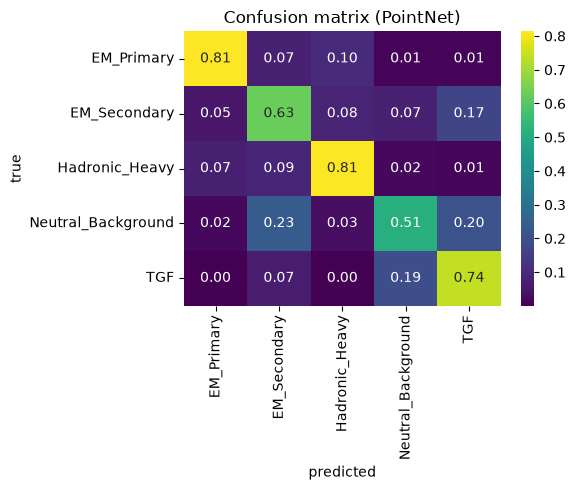

In [20]:
pred_pointnet = prob_pn.argmax(1)

print("macro-F1:", round(f1_score(y_int[te], pred_pointnet, average="macro"), 3))
print(classification_report(y_int[te], pred_pointnet, target_names=classes, digits=3))

cm = pd.crosstab(
        pd.Series(classes[y_int[te]], name="true"),
        pd.Series(classes[pred_pointnet], name="predicted"),
        normalize="index"
    ).reindex(index=classes, columns=classes, fill_value=0)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="viridis")
plt.title("Confusion matrix (PointNet)")
plt.tight_layout(); plt.show()

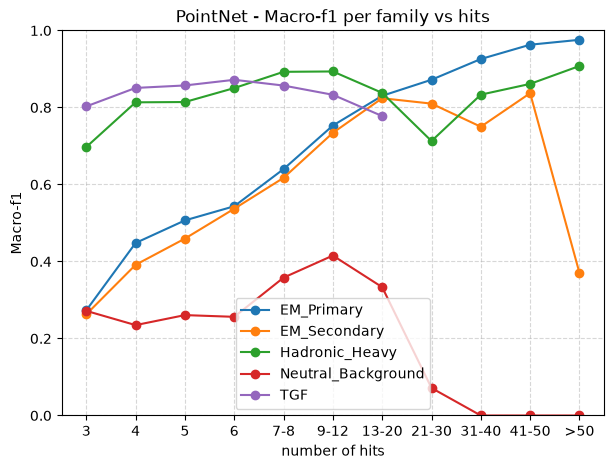

In [21]:
name = "PointNet"                      # "PointNet" / "GNN"
pred = prob_pn.argmax(1)
metric = "Macro-f1" # or Precision, Recall
if metric == "Macro-f1": metric_fn = f1_score
elif metric == "Precision": metric_fn = precision_score
else: metric_fn = recall_score

edges  = [2, 3, 4, 5, 6, 8, 12, 20, 30, 40, 50, np.inf]
labels = ["3", "4", "5", "6", "7-8", "9-12", "13-20", "21-30", "31-40", "41-50", ">50"]
hit_bins = pd.cut(n_hits[te], edges, labels=labels)
y_te = y_int[te]

plt.figure(figsize=(7, 5))
for k, fam in enumerate(classes):
    prec = [metric_fn(y_te[hit_bins == b] == k, pred[hit_bins == b] == k, zero_division=np.nan)
            for b in labels]
    plt.plot(labels, prec, "o-", label=fam)

plt.xlabel("number of hits"); plt.ylabel(metric); plt.ylim(0, 1)
plt.title(f"{name} - {metric} per family vs hits")
plt.grid(True, linestyle="--", alpha=0.5); plt.legend()
plt.show()

It reaches lower metrics wrt DeepSets but requires more computational resources ($\sim 25\text{--}33\text{ s/epochs}$). This may be caused by the use of the MAX operation instead of the mean and max pooling, loosing informations. 

# 03 - Graph Neural Network

**GNN** builds a graph linking voxels in a radius and perform 3 step of message *message passing* (`GraphConv`). 

In [22]:
gnn = build_gnn(len(classes))
# gnn = fit_eval(gnn, [H, V, G], tr, te, "GNN")      
sub_idx = np.random.default_rng(0).choice(tr, size=len(tr), replace=False)
pred_gnn = fit_eval(gnn, [H, V, G], sub_idx, te, "GNN", weight_all=w_all)

Epoch 1/30
315/315 - 49s - 155ms/step - accuracy: 0.6242 - loss: 1.1117 - val_accuracy: 0.6889 - val_loss: 0.9221 - learning_rate: 0.0010
Epoch 2/30
315/315 - 43s - 137ms/step - accuracy: 0.7070 - loss: 0.8986 - val_accuracy: 0.7316 - val_loss: 0.8306 - learning_rate: 0.0010
Epoch 3/30
315/315 - 45s - 144ms/step - accuracy: 0.7168 - loss: 0.8484 - val_accuracy: 0.7302 - val_loss: 0.8101 - learning_rate: 0.0010
Epoch 4/30
315/315 - 44s - 140ms/step - accuracy: 0.7204 - loss: 0.8249 - val_accuracy: 0.7314 - val_loss: 0.7848 - learning_rate: 0.0010
Epoch 5/30
315/315 - 42s - 134ms/step - accuracy: 0.7236 - loss: 0.8070 - val_accuracy: 0.7488 - val_loss: 0.7707 - learning_rate: 0.0010
Epoch 6/30
315/315 - 48s - 151ms/step - accuracy: 0.7253 - loss: 0.7954 - val_accuracy: 0.7563 - val_loss: 0.7647 - learning_rate: 0.0010
Epoch 7/30
315/315 - 46s - 147ms/step - accuracy: 0.7282 - loss: 0.7889 - val_accuracy: 0.7589 - val_loss: 0.7604 - learning_rate: 0.0010
Epoch 8/30
315/315 - 39s - 124ms/s

In [23]:
# 1) how many neighbours per hit does the graph give? (if ~0, the GNN cannot help)
adj = Adjacency(0.40)(H[te][:, :, :3].astype("float32"), V[te].astype("float32"))
nb = np.array(adj).sum(-1)                         # neighbours per hit
mean_nb = (nb * V[te]).sum(1) / V[te].sum(1)       # per event
print(pd.Series(mean_nb).describe().round(2))

# 2) macro-F1 by number of hits (where does the GNN gain?)
nh = V[te].sum(1)
bins = pd.cut(nh, [2, 3, 4, 6, 10, 20, 64], labels=["3", "4", "5-6", "7-10", "11-20", ">20"])
gnn_pred = gnn.predict([H[te], V[te], G[te]]).argmax(1)
for b in bins.categories:
    m = (bins == b)
    print(b, m.sum(), round(f1_score(y_int[te][m], gnn_pred[m], average="macro"), 3))

count    44790.00
mean         1.29
std          1.19
min          0.00
25%          0.57
50%          1.00
75%          1.88
max          8.44
dtype: float64
1400/1400 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step
3 18347 0.475
4 8925 0.558
5-6 7341 0.603
7-10 4321 0.692
11-20 2375 0.721
>20 3481 0.696


macro-F1: 0.658
                    precision    recall  f1-score   support

        EM_Primary      0.800     0.844     0.821      4243
      EM_Secondary      0.454     0.603     0.518      4271
    Hadronic_Heavy      0.853     0.805     0.828      5869
Neutral_Background      0.196     0.469     0.277      2567
               TGF      0.934     0.770     0.844     27840

          accuracy                          0.748     44790
         macro avg      0.647     0.698     0.658     44790
      weighted avg      0.822     0.748     0.776     44790



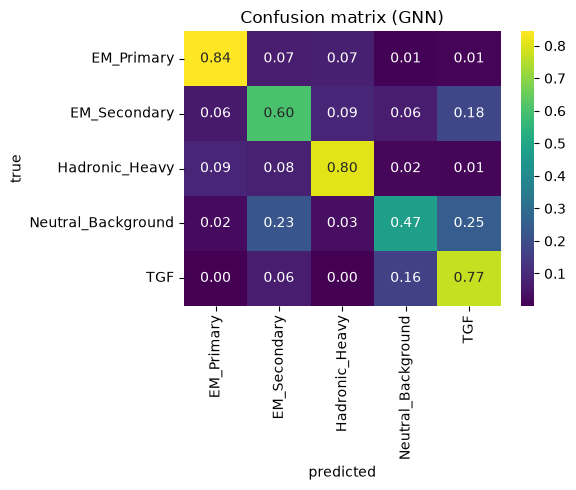

In [24]:
print("macro-F1:", round(f1_score(y_int[te], gnn_pred, average="macro"), 3))
print(classification_report(y_int[te], gnn_pred, target_names=classes, digits=3))

cm = pd.crosstab(
        pd.Series(classes[y_int[te]], name="true"),
        pd.Series(classes[gnn_pred], name="predicted"),
        normalize="index"
    ).reindex(index=classes, columns=classes, fill_value=0)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="viridis")
plt.title("Confusion matrix (GNN)")
plt.tight_layout(); plt.show()

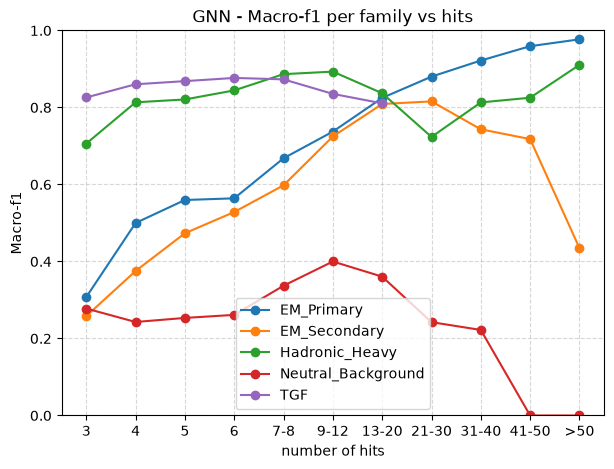

In [25]:
name = "GNN"
pred = gnn_pred
metric = "Macro-f1" # or Precision, Recall
if metric == "Macro-f1": metric_fn = f1_score
elif metric == "Precision": metric_fn = precision_score
else: metric_fn = recall_score

edges  = [2, 3, 4, 5, 6, 8, 12, 20, 30, 40, 50, np.inf]
labels = ["3", "4", "5", "6", "7-8", "9-12", "13-20", "21-30", "31-40", "41-50", ">50"]
hit_bins = pd.cut(n_hits[te], edges, labels=labels)
y_te = y_int[te]

plt.figure(figsize=(7, 5))
for k, fam in enumerate(classes):
    prec = [metric_fn(y_te[hit_bins == b] == k, pred[hit_bins == b] == k, zero_division=np.nan)
            for b in labels]
    plt.plot(labels, prec, "o-", label=fam)

plt.xlabel("number of hits"); plt.ylabel(metric); plt.ylim(0, 1)
plt.title(f"{name} - {metric} per family vs hits")
plt.grid(True, linestyle="--", alpha=0.5); plt.legend()
plt.show()

The graphs are very sparse: a hit has on average 1.29 neighbours (median 1), because most events have only a few hits (41% of the test events have 3 hits). This limits the information that neighbour relations can add. The GNN is the slowest model (26–35 s per epoch).

# 04 - Results and comparison

In [26]:
w_eq = 1.0 / np.bincount(y_int[te])[y_int[te]]          # every family weighs the same
probs = {"DeepSets": pred_deepset, "PointNet": prob_pn, "GNN": pred_gnn}
for name, p in probs.items():
    print(name, round(f1_score(y_int[te], p.argmax(1), average="macro", sample_weight=w_eq), 3))

DeepSets 0.695
PointNet 0.7
GNN 0.694


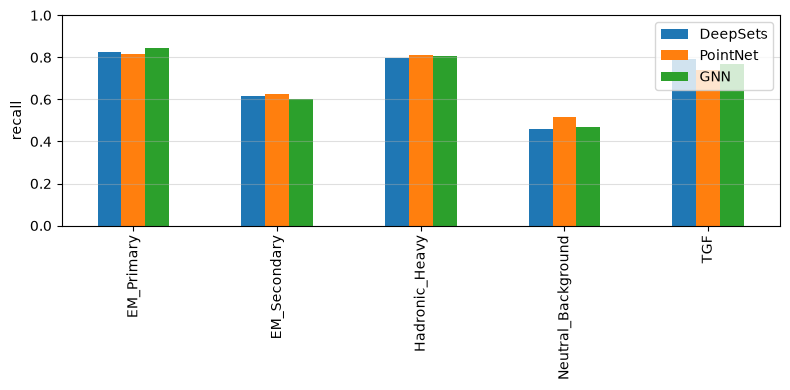

In [27]:
rec = pd.DataFrame({n: recall_score(y_int[te], p.argmax(1), average=None) for n, p in probs.items()},
                   index=classes)
rec.plot.bar(figsize=(8, 4)); plt.ylabel("recall"); plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.4); plt.tight_layout(); plt.show()

In [28]:
import time
for n, m in {"DeepSets": deepset_model, "PointNet": pointnet, "GNN": gnn}.items():
    t0 = time.time(); m.predict([H[te][:2048], V[te][:2048], G[te][:2048]], verbose=0)
    print(n, m.count_params(), "params,", round((time.time() - t0) / 2048 * 1000, 3), "ms/event")

DeepSets 30213 params, 0.186 ms/event
PointNet 83653 params, 0.117 ms/event
GNN 51013 params, 0.189 ms/event


## 04.1 - Confidence analysis

Here we analize the confidence threshsold impact on metrics:

In [29]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Dizionario con le probabilità predette sul test set dai 3 modelli
models_probs = {
    "DeepSets": pred_deepset,
    "PointNet": prob_pn,
    "GNN": gnn.predict([H[te], V[te], G[te]], verbose=0),
}

thresholds = [0.0, 0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
y_te = y_int[te]
n_classes = len(classes)

tables_by_model = {}

for model_name, yprobs in models_probs.items():
  ypred = yprobs.argmax(axis=1)
  max_probs = yprobs.max(axis=1)
  conf_rows = []

  for thr in thresholds:
    mask = max_probs >= thr
    n_kept = int(mask.sum())
    coverage = (n_kept / len(y_te)) * 100

    # Calcola le metriche solo se sono presenti tutte le classi
    if n_kept > 0 and len(np.unique(y_te[mask])) == n_classes:
      macro_f1 = f1_score(y_te[mask], ypred[mask], average="macro")
      bal_acc = balanced_accuracy_score(y_te[mask], ypred[mask])
      acc = accuracy_score(y_te[mask], ypred[mask])
    else:
      macro_f1, bal_acc, acc = np.nan, np.nan, np.nan

    conf_rows.append({
        "Threshold": thr,
        "Events_Kept": n_kept,
        "Coverage_%": round(coverage, 1),
        "Macro_F1": round(macro_f1, 4),
        "Balanced_Acc": round(bal_acc, 4),
        "Accuracy": round(acc, 4),
    })

  df_conf = pd.DataFrame(conf_rows)
  tables_by_model[model_name] = df_conf
  print(f"\n=== {model_name} | Tot. events in test set: {len(y_te)} ===")
  print(df_conf.to_string(index=False))


=== DeepSets | Tot. events in test set: 44790 ===
 Threshold  Events_Kept  Coverage_%  Macro_F1  Balanced_Acc  Accuracy
      0.00        44790       100.0    0.6654        0.6984    0.7602
      0.50        35110        78.4    0.7259        0.7567    0.8269
      0.60        27181        60.7    0.7759        0.7932    0.8922
      0.70        20463        45.7    0.8166        0.8237    0.9314
      0.75        17173        38.3    0.8407        0.8434    0.9463
      0.80        13935        31.1    0.8609        0.8611    0.9580
      0.85        10991        24.5    0.8831        0.8724    0.9706
      0.90         8442        18.8    0.9109        0.8833    0.9816
      0.95         6575        14.7    0.8327        0.7653    0.9913

=== PointNet | Tot. events in test set: 44790 ===
 Threshold  Events_Kept  Coverage_%  Macro_F1  Balanced_Acc  Accuracy
      0.00        44790       100.0    0.6544        0.7010    0.7320
      0.50        34691        77.5    0.7205        0.763

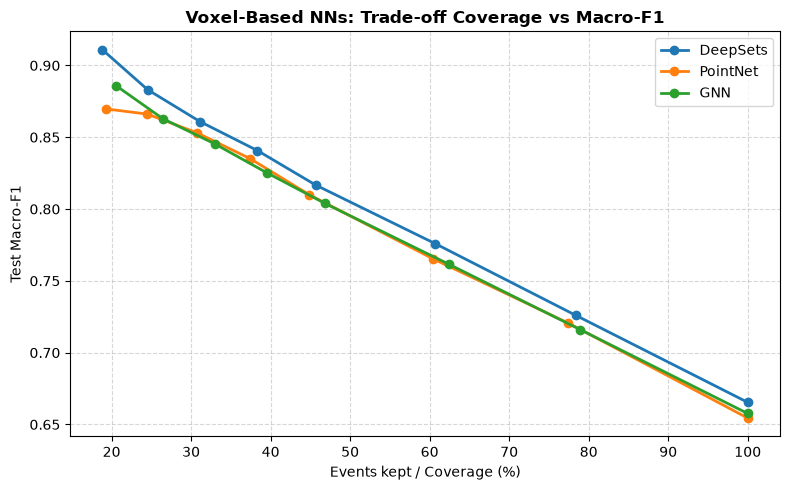

In [30]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

thresholds = [0.0, 0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90]
models_probs = {
    "DeepSets": pred_deepset,
    "PointNet": prob_pn,
    "GNN": gnn.predict([H[te], V[te], G[te]], verbose=0),
}

y_te = y_int[te]
plt.figure(figsize=(8, 5))

for name, probs in models_probs.items():
  max_p = probs.max(axis=1)
  preds = probs.argmax(axis=1)
  covs, f1s = [], []
  for thr in thresholds:
    m = max_p >= thr
    if m.sum() > 0 and len(np.unique(y_te[m])) == len(classes):
      covs.append(m.mean() * 100)
      f1s.append(f1_score(y_te[m], preds[m], average="macro"))
  plt.plot(covs, f1s, "o-", lw=2, label=name)

plt.xlabel("Events kept / Coverage (%)")
plt.ylabel("Test Macro-F1")
plt.title("Voxel-Based NNs: Trade-off Coverage vs Macro-F1", fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Unlike the tabular case, macro-F1 is not monotonic.

## 04.2 - Results comparison

  Models  Macro-F1  Balanced Accuracy  Weighted F1
     GNN    0.6576             0.6983       0.7762
PointNet    0.6544             0.7010       0.7660
DeepSets    0.6654             0.6984       0.7863


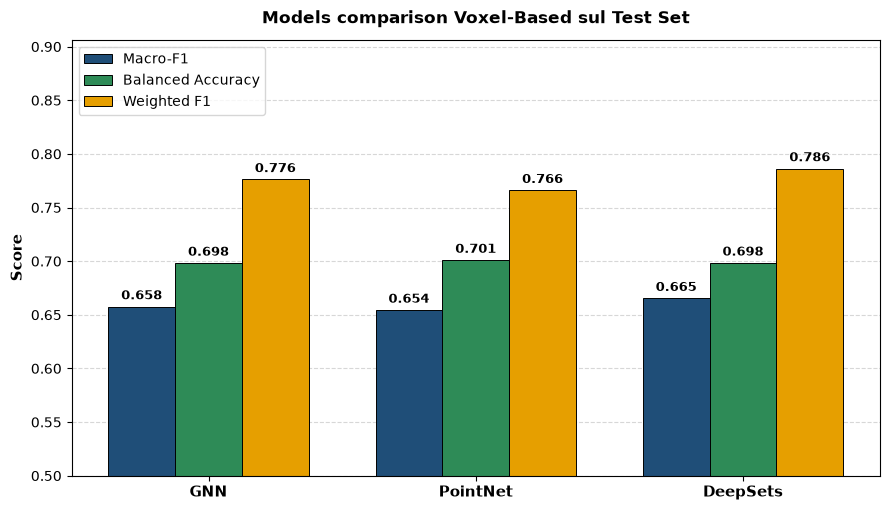

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, f1_score

# Predizioni estratte dinamicamente dai modelli già presenti nel notebook
predictions_dict = {
    "GNN": gnn_pred,
    "PointNet": pred_pointnet,
    "DeepSets": pred_deepset.argmax(axis=1),
}

# Calcolo automatico delle metriche sul test set (y_int[te])
y_true = y_int[te]
records = []

for name, y_pred in predictions_dict.items():
  records.append({
      "Models": name,
      "Macro-F1": f1_score(y_true, y_pred, average="macro"),
      "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
      "Weighted F1": f1_score(y_true, y_pred, average="weighted"),
  })

df_comp = pd.DataFrame(records)
print(df_comp.round(4).to_string(index=False))

# Plot a barre raggruppate
metrics = ["Macro-F1", "Balanced Accuracy", "Weighted F1"]
colors = ["#1f4e78", "#2e8b57", "#e69f00"]
x = np.arange(len(df_comp))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5.2))

for i, (metric, color) in enumerate(zip(metrics, colors)):
  offset = (i - 1) * width
  rects = ax.bar(
      x + offset,
      df_comp[metric],
      width,
      label=metric,
      color=color,
      edgecolor="black",
      linewidth=0.7,
  )
  ax.bar_label(rects, fmt="%.3f", padding=3, fontsize=9.5, fontweight="bold")

ax.set_ylabel("Score", fontsize=11, fontweight="bold")
ax.set_title(
    "Models comparison Voxel-Based sul Test Set",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
ax.set_xticks(x)
ax.set_xticklabels(df_comp["Models"], fontsize=10.5, fontweight="bold")
ax.set_ylim(0.50, min(1.0, df_comp[metrics].max().max() + 0.12))
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

# APPENDIX 1 - Architectures' plot


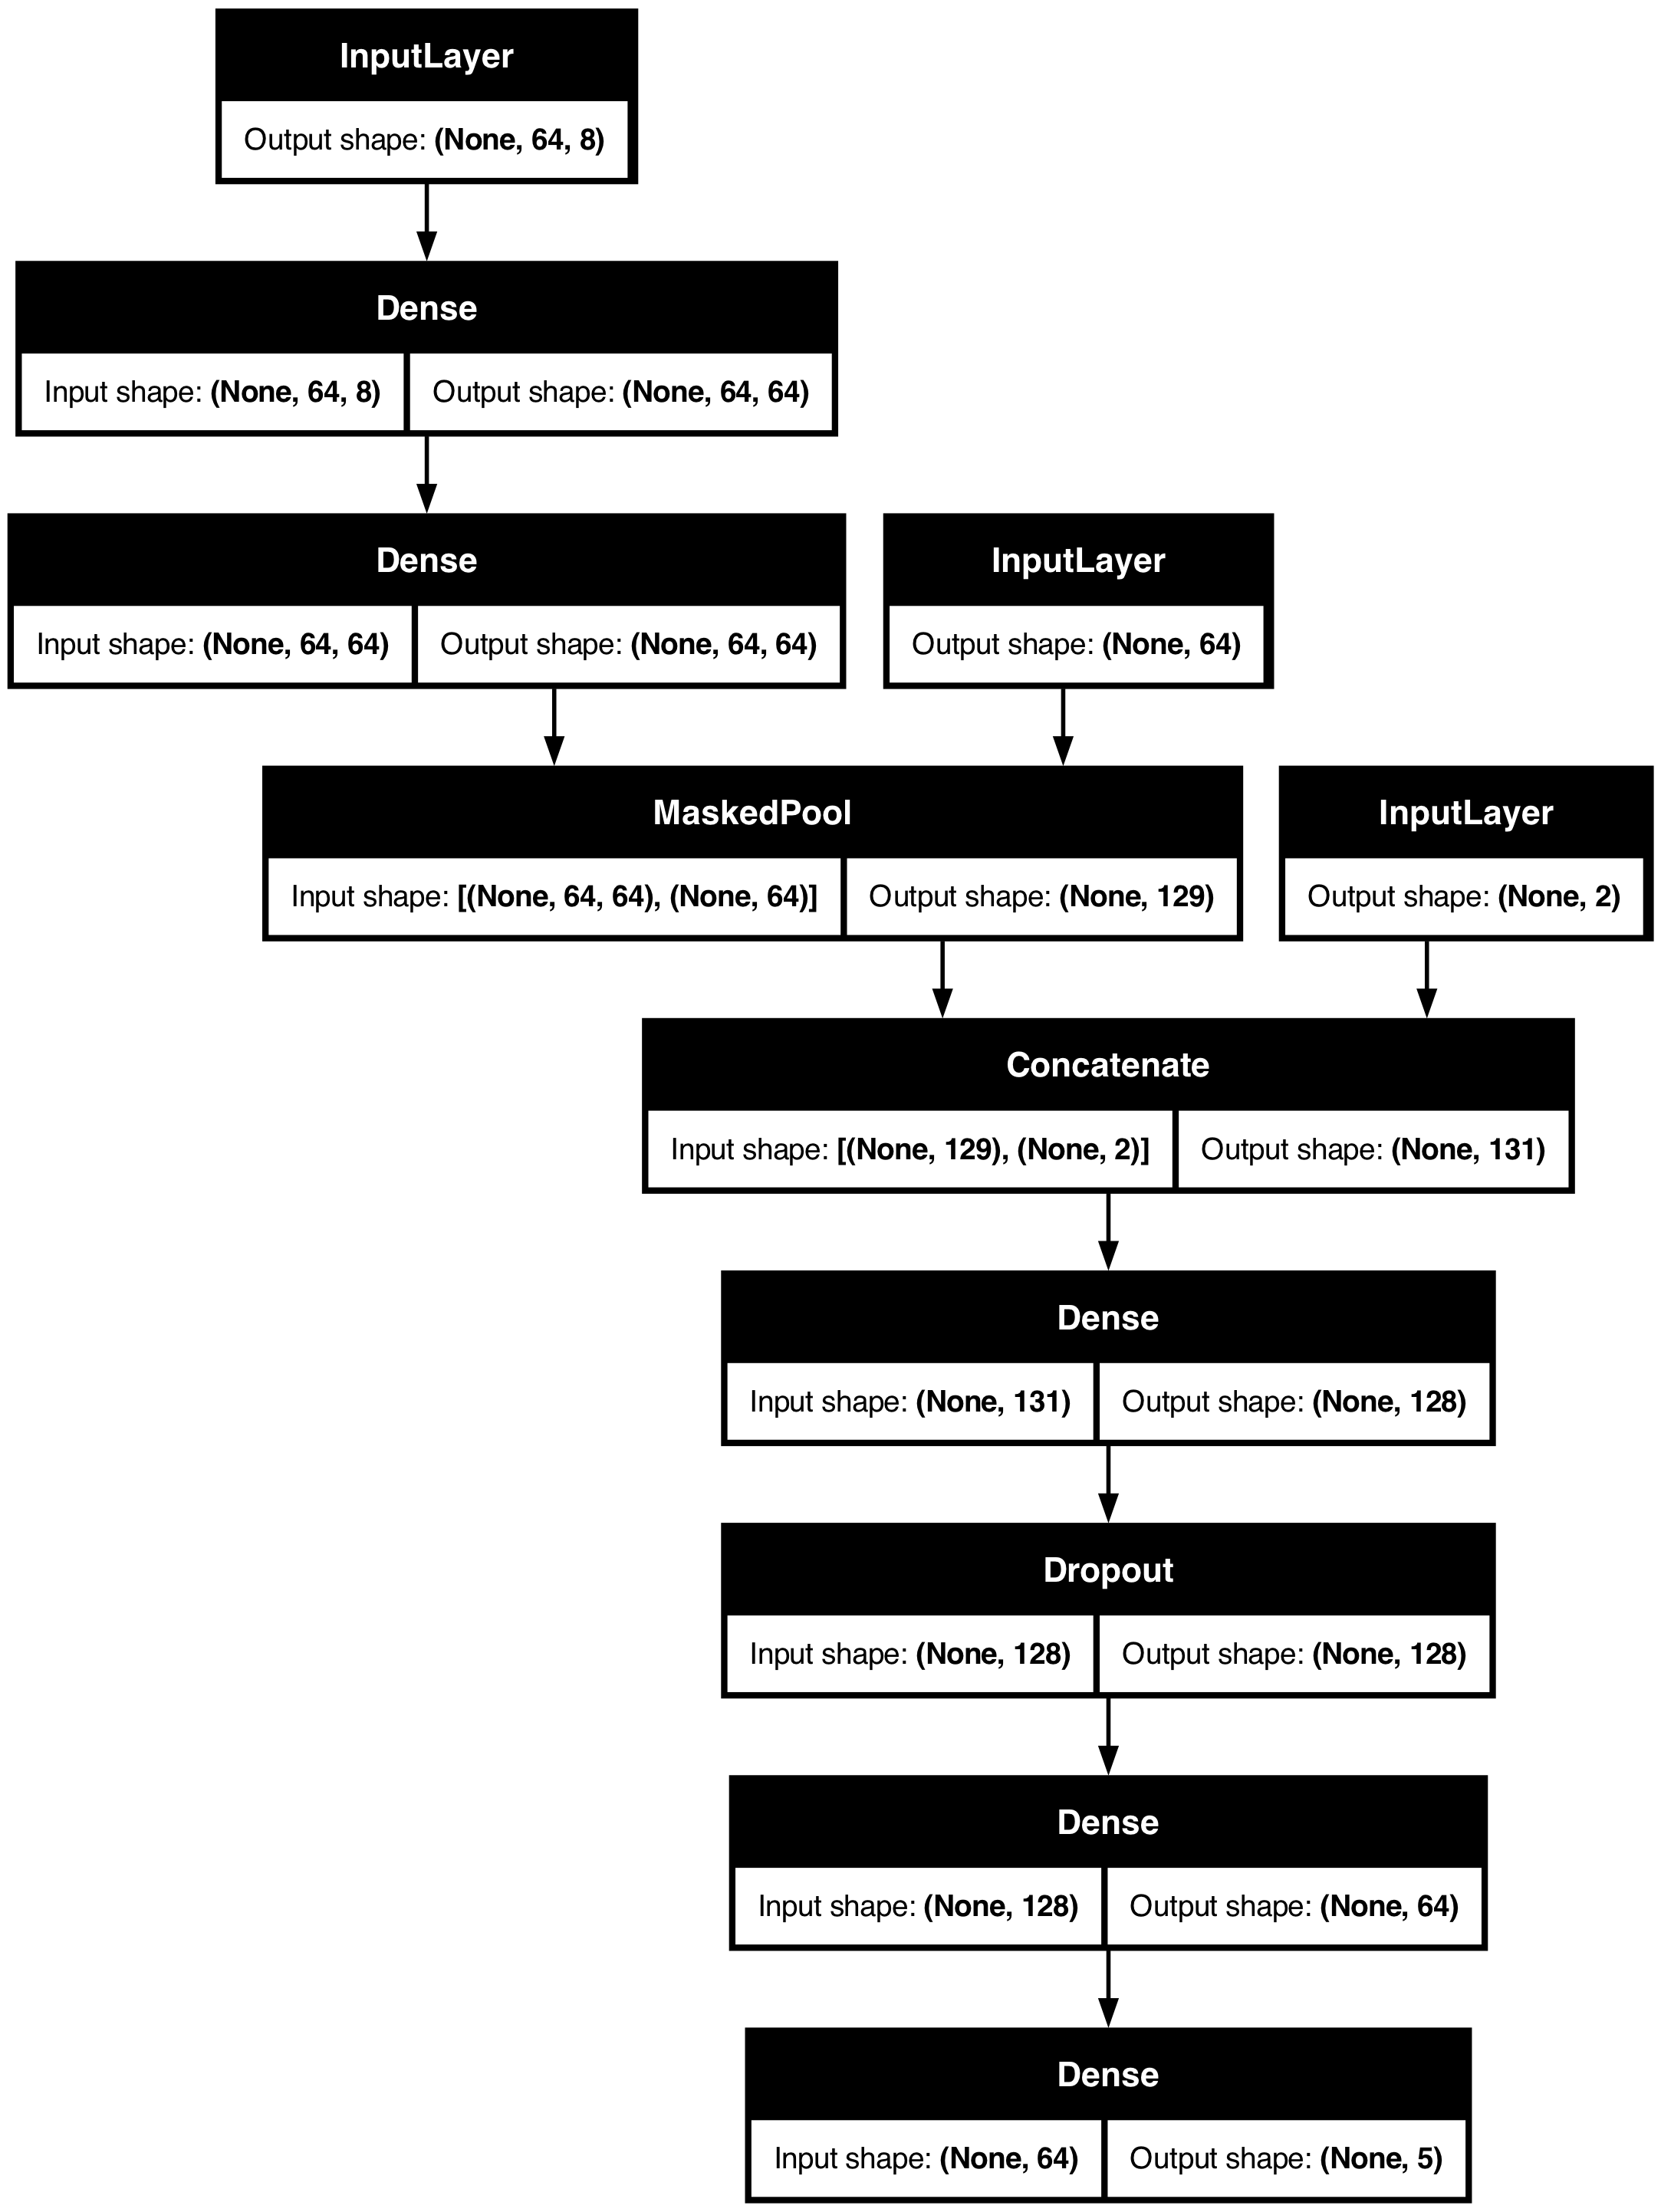

In [34]:
import pydot
keras.utils.plot_model(deepset_model, show_shapes=True)

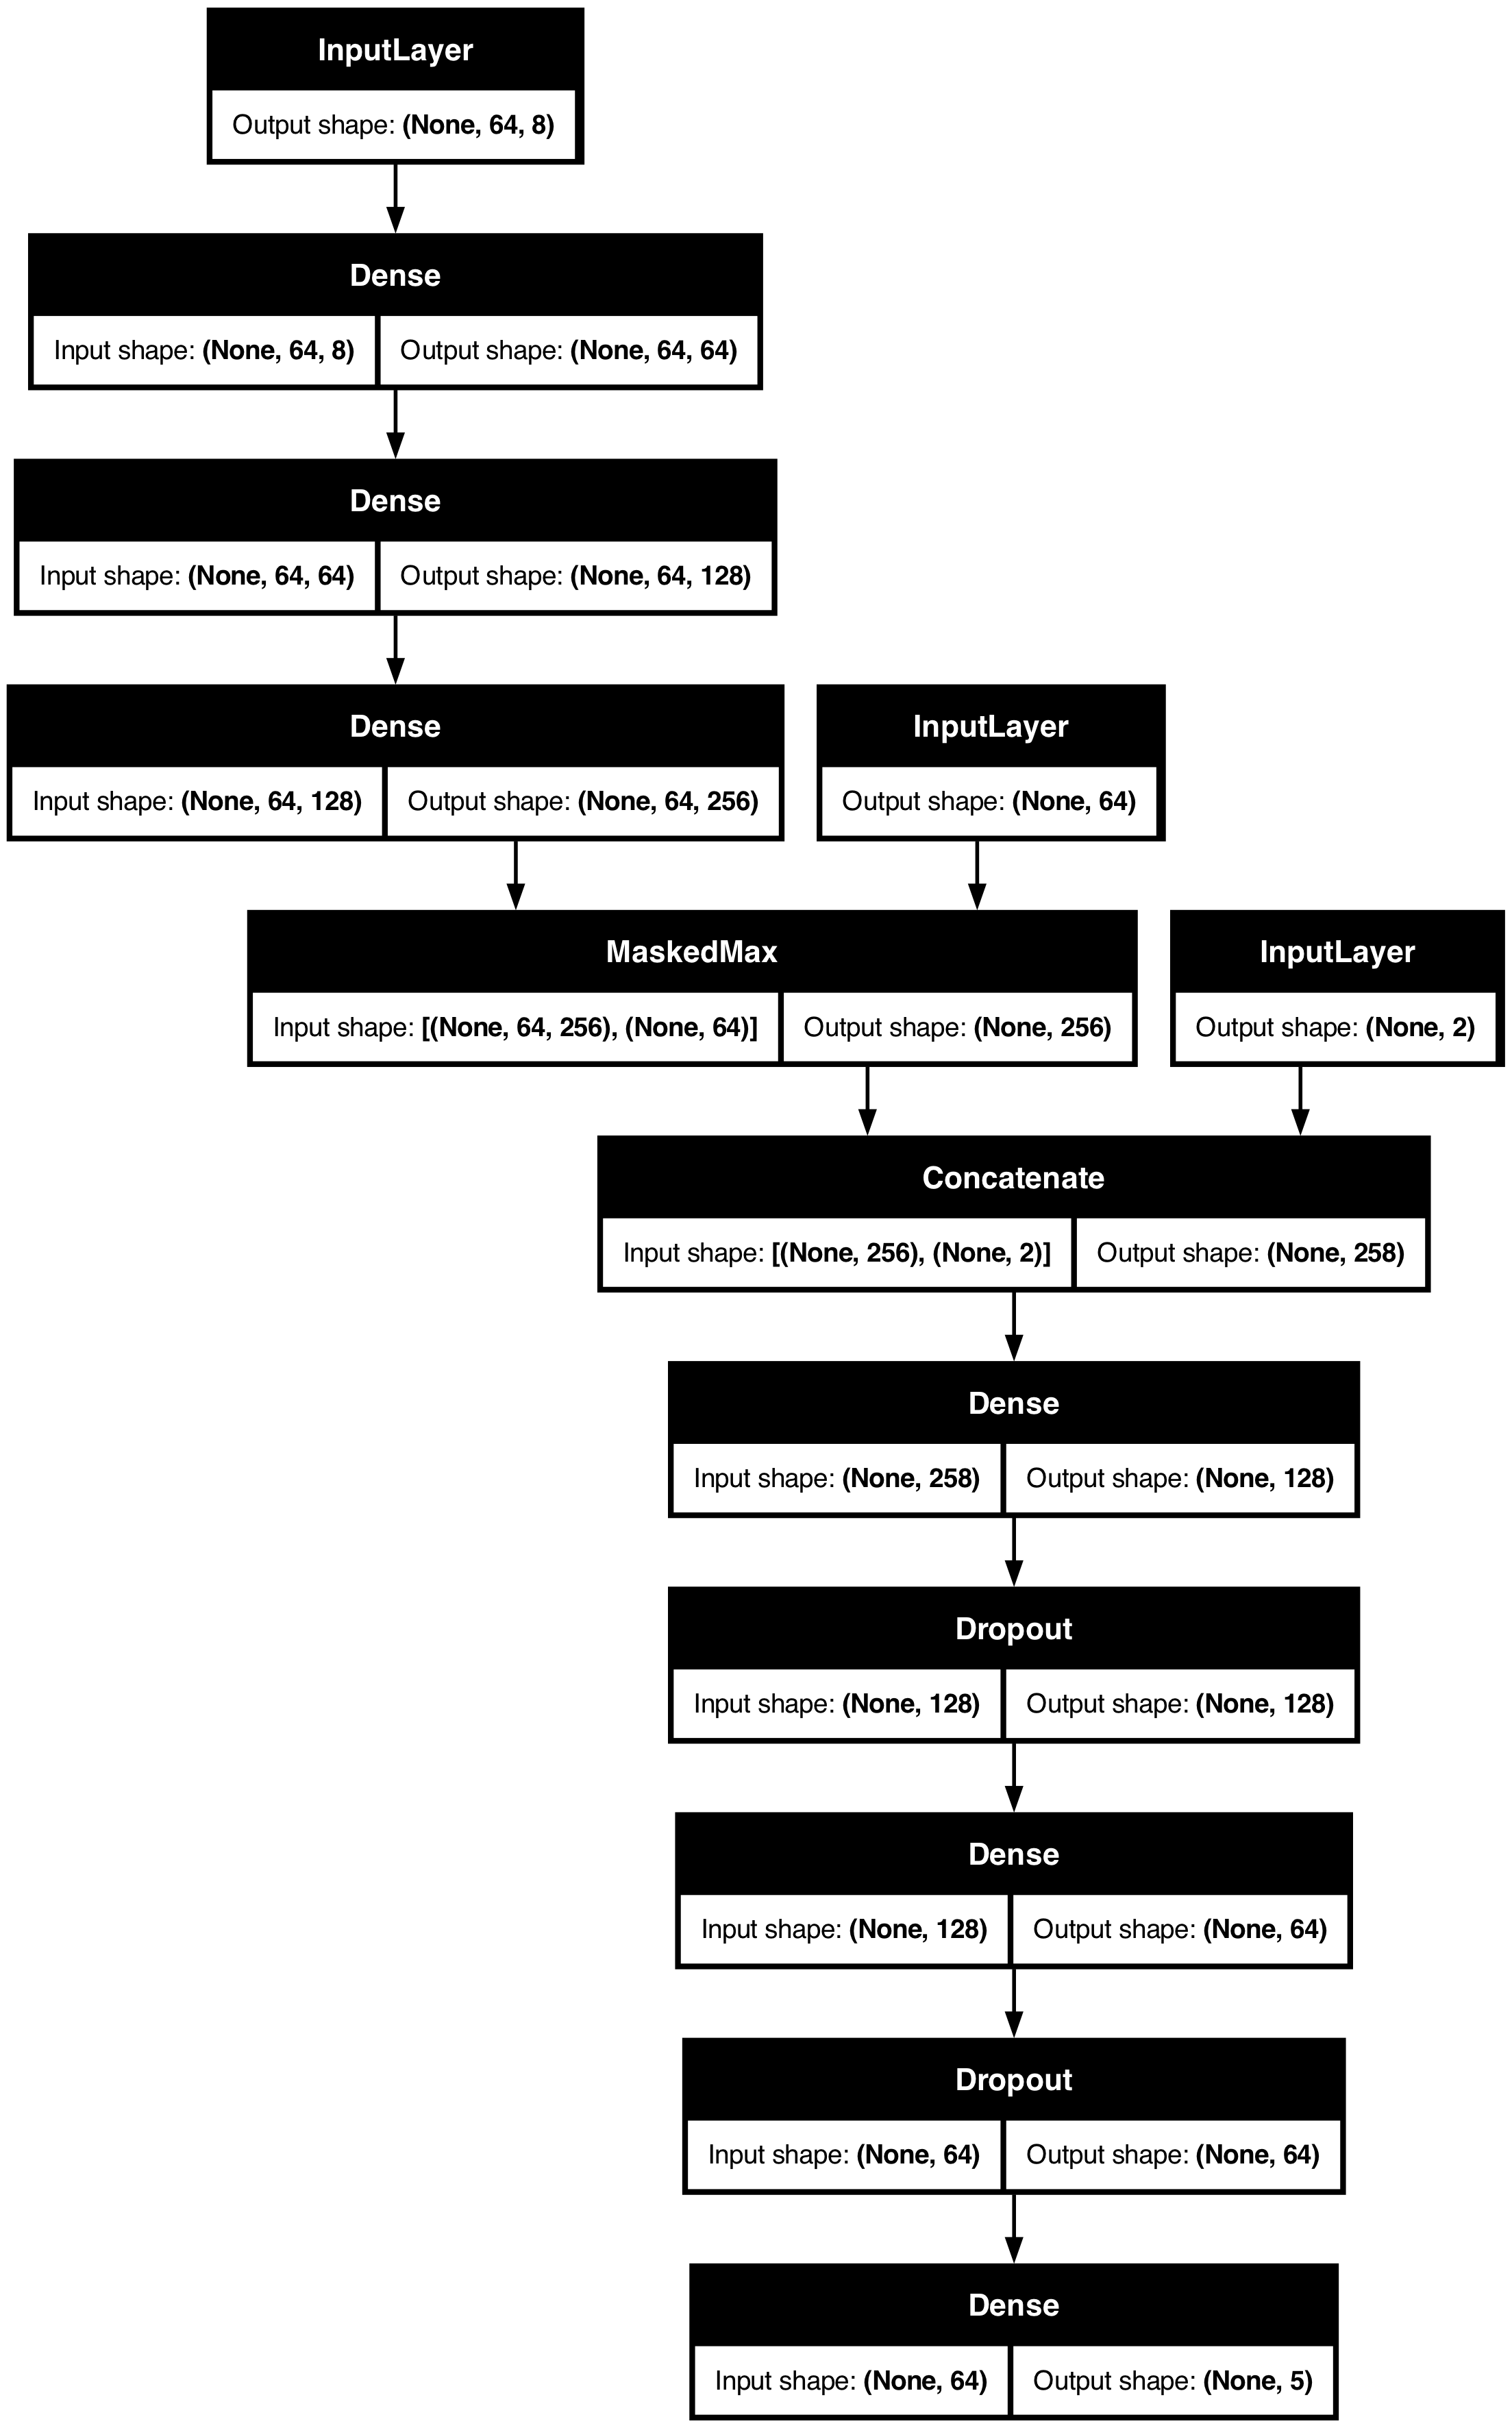

In [35]:
keras.utils.plot_model(pointnet, show_shapes=True)

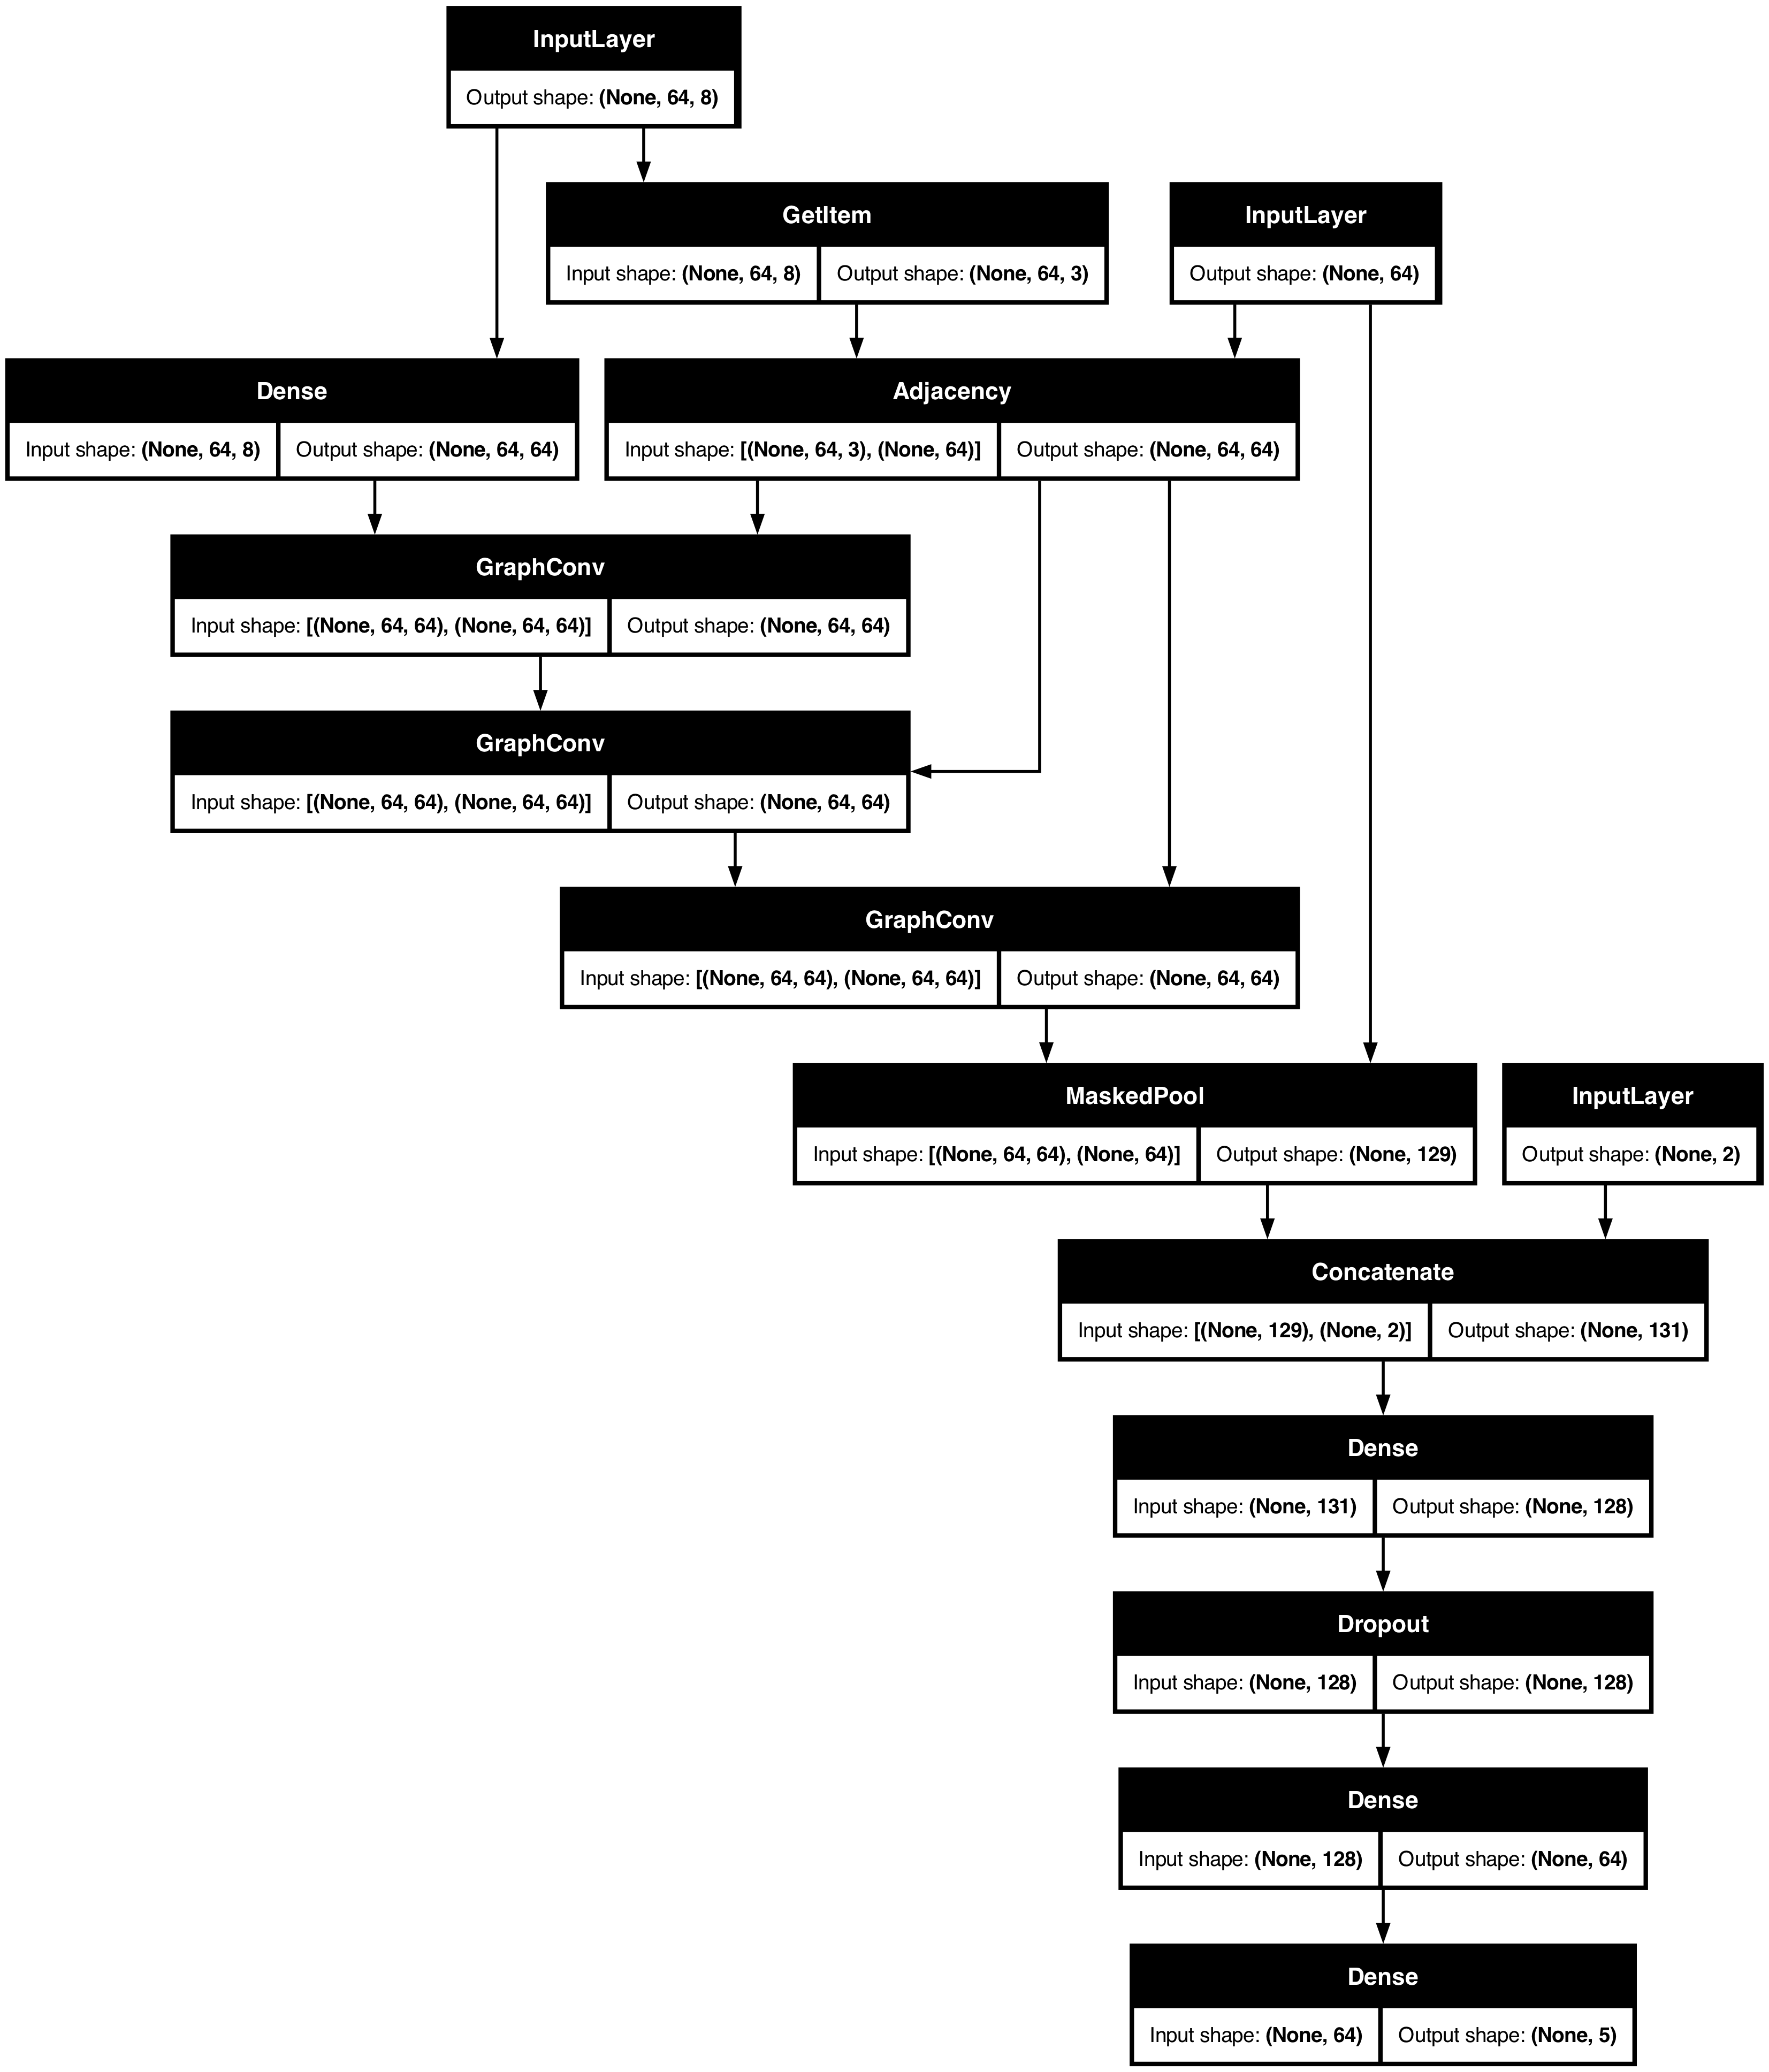

In [36]:
keras.utils.plot_model(gnn, show_shapes=True)